preprocessing pipeline.. 
reading all xcel sjheet sheet_name=none, den stacking into 2 tables, split by accident and alarm event.. pdconcat()

look at incident column and filter out duplicate.
ID standardization, data cleaning, converting number to string, stripping whitespace etc.
behavior stats and metric - avg speed, max speed total alarm duration.

encode and export to csv when labelled with 1 or 0..

In [2]:
import pandas as pd
import numpy as np

def clean_id(series):
    return (
        series.dropna()
        .astype(str)
        .str.strip()
        .str.replace(r'\.0$', '', regex=True)
    )

acc_sheets = pd.read_excel('Traffic Accident Database 2024.xlsx', sheet_name=None)
df_acc = pd.concat(acc_sheets.values(), ignore_index=True)

status_col = [c for c in df_acc.columns if 'Duplicate' in str(c)][0]
print("Accident status categories:", df_acc[status_col].dropna().unique())

df_acc = df_acc[~df_acc[status_col].astype(str).str.contains('Duplicate', case=False, na=False)]
df_acc['Driver_ID'] = clean_id(df_acc['Employee No'])
df_acc = df_acc[df_acc['Driver_ID'] != '']

accident_drivers = set(df_acc['Driver_ID'].unique())
print("Total unique drivers with Q1 accidents:", len(accident_drivers))

p1_sheets = pd.read_excel('Mar24_part1.xlsx', sheet_name=None)
p2_sheets = pd.read_excel('Mar24_part2.xlsx', sheet_name=None)

df_alarms = pd.concat(
    list(p1_sheets.values()) + list(p2_sheets.values()),
    ignore_index=True
)
print("Total raw alarm rows loaded:", len(df_alarms))

df_alarms = df_alarms.dropna(subset=['Driver', 'Alarm type']).copy()
df_alarms['Driver_ID'] = clean_id(df_alarms['Driver'])
df_alarms = df_alarms[df_alarms['Driver_ID'] != '']
df_alarms['Alarm type'] = df_alarms['Alarm type'].astype(str).str.strip()

alarm_counts = pd.crosstab(df_alarms['Driver_ID'], df_alarms['Alarm type'])
alarm_counts['Total_Alarms'] = alarm_counts.sum(axis=1)

extra_stats = df_alarms.groupby('Driver_ID').agg(
    Avg_Speed=('speed(km/h)', 'mean'),
    Max_Speed=('speed(km/h)', 'max'),
    Total_Alarm_Duration=('Alarm duration', 'sum')
)

df_drivers = alarm_counts.join(extra_stats).reset_index()
df_drivers['At_Risk'] = df_drivers['Driver_ID'].isin(accident_drivers).astype(int)

df_drivers.to_csv('driver_features.csv', index=False)

print("\nFinal aggregated driver dataset shape:", df_drivers.shape)
print("Class distribution (0 = Safe, 1 = Accident):")
print(df_drivers['At_Risk'].value_counts())
print("\nPreview of engineered features:")
print(df_drivers.head())

Accident status categories: ['Duplicate ' 'CAT 1' 'DD' 'Duplicate  ' 'Near Miss' 'Alleged' 'NM' ' '
 'Duplicate']
Total unique drivers with Q1 accidents: 175
Total raw alarm rows loaded: 4167176

Final aggregated driver dataset shape: (1544, 16)
Class distribution (0 = Safe, 1 = Accident):
At_Risk
0    1380
1     164
Name: count, dtype: int64

Preview of engineered features:
  Driver_ID  Fatigue Alert  Forward Collision Warning  Harsh Acceleration  \
0     10055              2                        512                 709   
1     10074             93                       1169                 138   
2     10102            185                        108                  24   
3     10138              1                        267                 129   
4     10151              1                          7                   1   

   Harsh Braking  Headway Monitoring Alert  Pedestrian Collision Alert  \
0           1864                         2                         104   
1          

what this output tell us? raw rows, unique drivers with Q1 accidents, categorized into 1544 unique bus drivers and 14 differentdanger fetures.
out of 175 unique drivers, 164 are high risk in march

step 1: Import libraries and obtain dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score

tf.random.set_seed(42)
np.random.seed(42)

df = pd.read_csv('driver_features.csv')
print("Dataset loaded successfully. Shape:", df.shape)

Dataset loaded successfully. Shape: (1544, 16)


Step 2: Explore dataset

In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nClass distribution (0 = Safe, 1 = At_Risk):")
print(df['At_Risk'].value_counts())

print("\nSummary statistics:")
display(df.describe().round(2))

Missing values per column:
Driver_ID                     0
Fatigue Alert                 0
Forward Collision Warning     0
Harsh Acceleration            0
Harsh Braking                 0
Headway Monitoring Alert      0
Pedestrian Collision Alert    0
Sharp Cornering               0
Speeding                      0
Swaying                       0
Yawn                          0
Total_Alarms                  0
Avg_Speed                     0
Max_Speed                     0
Total_Alarm_Duration          0
At_Risk                       0
dtype: int64

Class distribution (0 = Safe, 1 = At_Risk):
At_Risk
0    1380
1     164
Name: count, dtype: int64

Summary statistics:


,Driver_ID,Fatigue Alert,Forward Collision Warning,Harsh Acceleration,Harsh Braking,Headway Monitoring Alert,Pedestrian Collision Alert,Sharp Cornering,Speeding,Swaying,Yawn,Total_Alarms,Avg_Speed,Max_Speed,Total_Alarm_Duration,At_Risk
count,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00,1544.00
mean,33540.29,22.37,614.36,261.83,1396.54,90.46,103.95,28.57,1.60,0.15,43.95,2563.78,22.01,60.71,11925.78,0.11
std,19220.84,133.12,399.70,254.59,783.87,106.49,62.53,35.63,5.21,0.95,70.22,1357.00,3.58,5.28,6456.62,0.31
min,10055.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,5.00,5.00,3.00,0.00
25%,20742.50,0.00,313.00,95.00,836.00,17.00,62.00,5.00,0.00,0.00,4.00,1578.50,19.98,59.00,7244.25,0.00
50%,26877.00,1.00,556.50,195.50,1319.00,54.00,98.00,16.00,0.00,0.00,17.00,2466.50,21.66,61.00,11474.50,0.00
75%,35065.25,6.25,844.25,353.75,1880.00,129.00,137.00,38.25,1.00,0.00,53.00,3457.50,23.55,63.00,15950.25,0.00
max,74687.00,4004.00,2833.00,2433.00,4453.00,843.00,724.00,265.00,77.00,19.00,650.00,7949.00,57.43,70.00,43732.00,1.00


step 3: preprocess dataset

In [5]:
from sklearn.preprocessing import StandardScaler

exclude_cols = ['Driver_ID', 'At_Risk', 'Risk_Probability', 'Risk_Tier']
feature_cols = [c for c in df.columns if c not in exclude_cols]

X = df[feature_cols].fillna(0)
y = df['At_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

class_weights = {0: 1.0, 1: 3.5}

Step 4: Set up ANN architecture 

In [6]:
tf.random.set_seed(42)
np.random.seed(42)

model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(8, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

Step 5: Compile model

In [7]:
optimizer = keras.optimizers.Adam(learning_rate=0.0005)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

Step 6: Training defined model

In [8]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=25,
    batch_size=64,
    validation_split=0.2,
    class_weight={0: 1.0, 1: 3.5},
    verbose=1
)

Epoch 1/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.5698 - auc: 0.5147 - loss: 0.9296 - val_accuracy: 0.4534 - val_auc: 0.5308 - val_loss: 0.7099
Epoch 2/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6468 - auc: 0.4926 - loss: 0.9012 - val_accuracy: 0.6032 - val_auc: 0.5617 - val_loss: 0.6753
Epoch 3/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6650 - auc: 0.5165 - loss: 0.8693 - val_accuracy: 0.7004 - val_auc: 0.5756 - val_loss: 0.6451
Epoch 4/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7045 - auc: 0.5141 - loss: 0.8604 - val_accuracy: 0.7652 - val_auc: 0.5844 - val_loss: 0.6189
Epoch 5/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7156 - auc: 0.5314 - loss: 0.8683 - val_accuracy: 0.8097 - val_auc: 0.5792 - val_loss: 0.5956
Epoch 6/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7267 - auc: 0.4665 - loss: 0.8838 - val_accuracy: 0.8421 - val_auc: 0.5711 - val_loss: 0.5794
Epoch 7/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/

Step 7: Plotting result

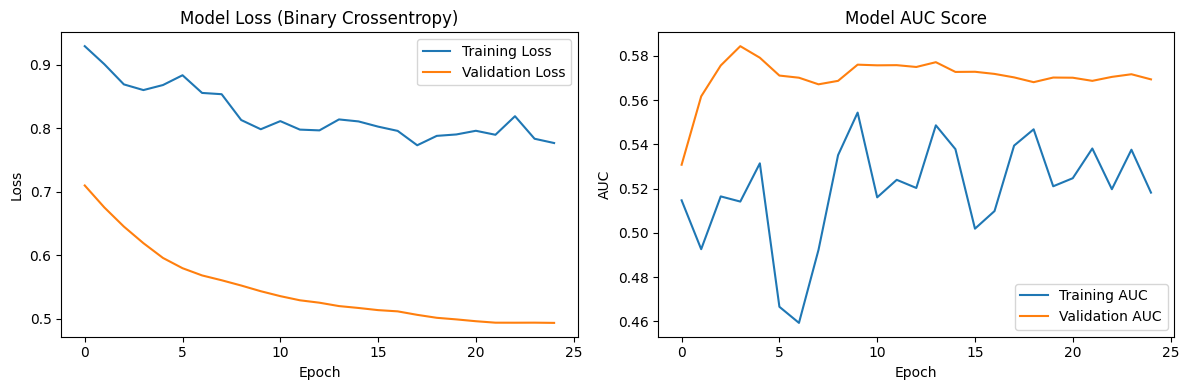

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='Training Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_title('Model Loss (Binary Crossentropy)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['auc'], label='Training AUC')
axes[1].plot(history.history['val_auc'], label='Validation AUC')
axes[1].set_title('Model AUC Score')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC')
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
probs = model.predict(X_test_scaled, verbose=0).flatten()
preds = (probs >= 0.40).astype(int)

print(f"Test ROC-AUC Score: {roc_auc_score(y_test, probs):.3f}")
print(classification_report(y_test, preds, digits=3))

X_all_scaled = scaler.transform(X)
df['Risk_Probability'] = (model.predict(X_all_scaled, verbose=0).flatten() * 100).round(1)
df['Risk_Tier'] = pd.cut(
    df['Risk_Probability'],
    bins=[-1, 33, 40, 100],
    labels=['Low', 'Medium', 'High']
)

df.to_csv('driver_predictions.csv', index=False)

Test ROC-AUC Score: 0.627
              precision    recall  f1-score   support

           0      0.913     0.761     0.830       276
           1      0.165     0.394     0.232        33

    accuracy                          0.722       309
   macro avg      0.539     0.577     0.531       309
weighted avg      0.833     0.722     0.766       309



Model 1: Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

lr_model = LogisticRegression(class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]
lr_preds = (lr_probs >= 0.50).astype(int)

print(f"Model 1 (Logistic Regression) Test ROC-AUC: {roc_auc_score(y_test, lr_probs):.3f}")
print(classification_report(y_test, lr_preds, digits=3))

Model 1 (Logistic Regression) Test ROC-AUC: 0.478
              precision    recall  f1-score   support

           0      0.897     0.507     0.648       276
           1      0.111     0.515     0.183        33

    accuracy                          0.508       309
   macro avg      0.504     0.511     0.415       309
weighted avg      0.813     0.508     0.598       309



Model 2: Random Forest

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train_scaled, y_train)

rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]
rf_preds = (rf_probs >= 0.50).astype(int)

print(f"Model 2 (Random Forest) Test ROC-AUC: {roc_auc_score(y_test, rf_probs):.3f}")
print(classification_report(y_test, rf_preds, digits=3))

Model 2 (Random Forest) Test ROC-AUC: 0.509
              precision    recall  f1-score   support

           0      0.908     0.681     0.778       276
           1      0.137     0.424     0.207        33

    accuracy                          0.654       309
   macro avg      0.523     0.553     0.493       309
weighted avg      0.826     0.654     0.717       309



Gradient Boosting

In [13]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
gb_model.fit(X_train_scaled, y_train)

gb_probs = gb_model.predict_proba(X_test_scaled)[:, 1]
gb_preds = (gb_probs >= 0.40).astype(int)

print(f"Model 3 (Gradient Boosting) Test ROC-AUC: {roc_auc_score(y_test, gb_probs):.3f}")
print(classification_report(y_test, gb_preds, digits=3))

Model 3 (Gradient Boosting) Test ROC-AUC: 0.566
              precision    recall  f1-score   support

           0      0.896     0.996     0.943       276
           1      0.500     0.030     0.057        33

    accuracy                          0.893       309
   macro avg      0.698     0.513     0.500       309
weighted avg      0.853     0.893     0.849       309



Comparison

                           Model  Test ROC-AUC
Primary Model: Tuned ANN (16->8)         0.627
      Model 3: Gradient Boosting         0.566
          Model 2: Random Forest         0.509
    Model 1: Logistic Regression         0.478


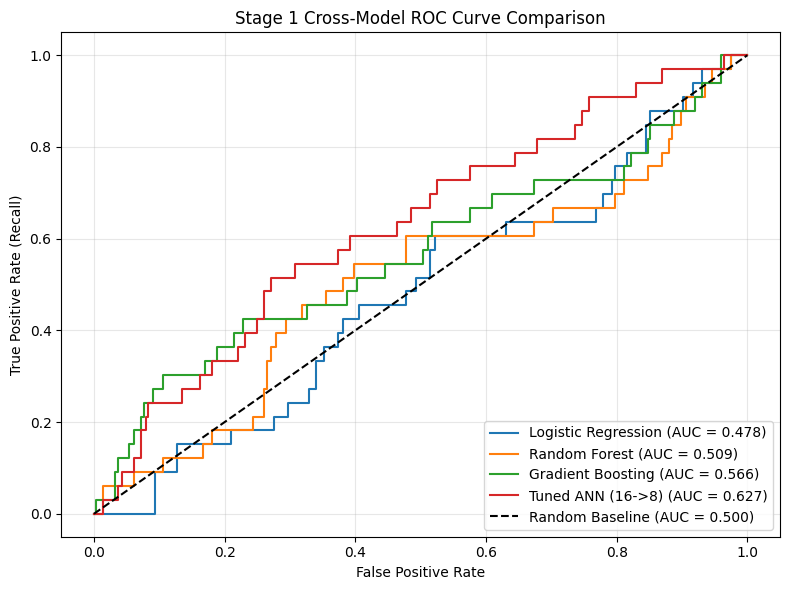

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

results_summary = pd.DataFrame({
    'Model': [
        'Model 1: Logistic Regression',
        'Model 2: Random Forest',
        'Model 3: Gradient Boosting',
        'Primary Model: Tuned ANN (16->8)'
    ],
    'Test ROC-AUC': [
        round(roc_auc_score(y_test, lr_probs), 3),
        round(roc_auc_score(y_test, rf_probs), 3),
        round(roc_auc_score(y_test, gb_probs), 3),
        round(roc_auc_score(y_test, probs), 3)
    ]
}).sort_values(by='Test ROC-AUC', ascending=False)

print(results_summary.to_string(index=False))

plt.figure(figsize=(8, 6))
for label, model_probs in [
    ('Logistic Regression', lr_probs),
    ('Random Forest', rf_probs),
    ('Gradient Boosting', gb_probs),
    ('Tuned ANN (16->8)', probs)
]:
    fpr, tpr, _ = roc_curve(y_test, model_probs)
    auc_val = roc_auc_score(y_test, model_probs)
    plt.plot(fpr, tpr, label=f"{label} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Baseline (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Stage 1 Cross-Model ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

hyperparameter comparison

In [15]:
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

X_raw_tr = np.asarray(X_train if 'X_train' in globals() else X_train_scaled)
X_raw_te = np.asarray(X_test if 'X_test' in globals() else X_test_scaled)

log_scaler = StandardScaler()
X_log_tr = log_scaler.fit_transform(np.log1p(np.clip(X_raw_tr, 0, None)))
X_log_te = log_scaler.transform(np.log1p(np.clip(X_raw_te, 0, None)))

def run_ann_experiment(name, feat_label, X_tr, X_te, layer_units, dropouts, lr, pos_weight):
    tf.keras.backend.clear_session()
    random.seed(42)
    np.random.seed(42)
    tf.random.set_seed(42)

    model_layers = [layers.Input(shape=(X_tr.shape[1],))]
    for units, drop in zip(layer_units, dropouts):
        model_layers.append(layers.Dense(units, activation='relu'))
        if drop > 0:
            model_layers.append(layers.Dropout(drop))
    model_layers.append(layers.Dense(1, activation='sigmoid'))

    exp_model = keras.Sequential(model_layers)
    exp_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc')]
    )

    exp_history = exp_model.fit(
        X_tr,
        y_train,
        epochs=25,
        batch_size=64,
        validation_split=0.2,
        class_weight={0: 1.0, 1: pos_weight},
        verbose=0
    )

    test_probs = exp_model.predict(X_te, verbose=0).flatten()
    final_train_auc = exp_history.history['auc'][-1]
    peak_val_auc = max(exp_history.history['val_auc'])
    test_auc = roc_auc_score(y_test, test_probs)

    return {
        'Run': name,
        'Features': feat_label,
        'Layers': ' -> '.join(map(str, layer_units)),
        'Dropout': '/'.join(map(str, dropouts)),
        'LR': lr,
        'Weight': pos_weight,
        'Train AUC': round(final_train_auc, 3),
        'Peak Val AUC': round(peak_val_auc, 3),
        'Test ROC-AUC': round(test_auc, 3)
    }

experiments = [
    run_ann_experiment('Run 1: Unscaled Baseline', 'Raw Unscaled', X_raw_tr, X_raw_te, [32, 16], [0.0, 0.0], 0.001, 1.0),
    run_ann_experiment('Run 2: Scaled Baseline', 'StandardScaler', X_train_scaled, X_test_scaled, [32, 16], [0.0, 0.0], 0.001, 1.0),
    run_ann_experiment('Run 3: Log-Transformed + Reg', 'Log1p + Scaled', X_log_tr, X_log_te, [32, 16], [0.2, 0.2], 0.001, 3.5),
    run_ann_experiment('Run 4: Deeper 3-Layer ANN', 'StandardScaler', X_train_scaled, X_test_scaled, [32, 16, 8], [0.4, 0.3, 0.2], 0.0005, 3.5)
]

stage2_df = pd.DataFrame(experiments)
print(stage2_df.to_string(index=False))


                         Run       Features        Layers     Dropout     LR  Weight  Train AUC  Peak Val AUC  Test ROC-AUC
    Run 1: Unscaled Baseline   Raw Unscaled      32 -> 16     0.0/0.0 0.0010     1.0      0.511         0.522         0.468
      Run 2: Scaled Baseline StandardScaler      32 -> 16     0.0/0.0 0.0010     1.0      0.650         0.608         0.533
Run 3: Log-Transformed + Reg Log1p + Scaled      32 -> 16     0.2/0.2 0.0010     3.5      0.622         0.568         0.528
   Run 4: Deeper 3-Layer ANN StandardScaler 32 -> 16 -> 8 0.4/0.3/0.2 0.0005     3.5      0.493         0.543         0.573


visualizations

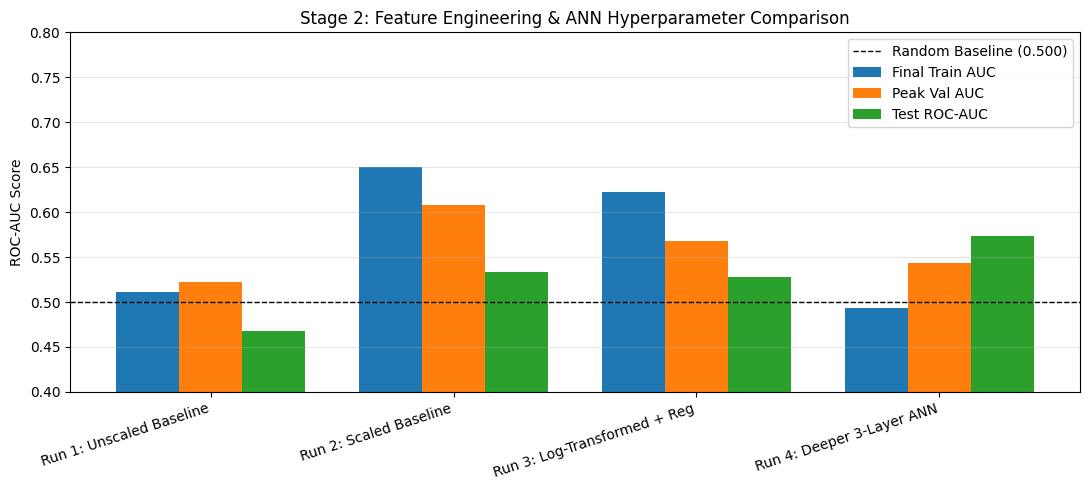

In [16]:
import matplotlib.pyplot as plt

x = np.arange(len(stage2_df))
width = 0.26

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - width, stage2_df['Train AUC'], width, label='Final Train AUC')
ax.bar(x, stage2_df['Peak Val AUC'], width, label='Peak Val AUC')
ax.bar(x + width, stage2_df['Test ROC-AUC'], width, label='Test ROC-AUC')

ax.axhline(0.50, color='black', linestyle='--', linewidth=1, label='Random Baseline (0.500)')
ax.set_ylabel('ROC-AUC Score')
ax.set_title('Stage 2: Feature Engineering & ANN Hyperparameter Comparison')
ax.set_xticks(x)
ax.set_xticklabels(stage2_df['Run'], rotation=18, ha='right')
ax.set_ylim(0.40, 0.80)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()